In [1]:
import os
HOME = os.getcwd()
print("HOME:", HOME)

import os

CHECKPOINT_PATH = os.path.join(HOME, "weights", "sam_vit_h_4b8939.pth")
print(CHECKPOINT_PATH, "; exist:", os.path.isfile(CHECKPOINT_PATH))

import torch

DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
MODEL_TYPE = "vit_h"
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator, SamPredictor

sam = sam_model_registry[MODEL_TYPE](checkpoint=CHECKPOINT_PATH).to(device=DEVICE)

HOME: /Users/abedinm/01_PYTHON_CODE
/Users/abedinm/01_PYTHON_CODE/weights/sam_vit_h_4b8939.pth ; exist: True


In [11]:
IMAGE_PATH = 'converted_images/m_3108503_ne_16_030_20211114.jpg'

In [27]:
import numpy as np

# default_box is going to be used if you will not draw any box on image above 1210.771484	1310.363159	1828.497192	1566.839844	617.725708	256.4766846
default_box = {'x': 15210, 'y': 7410, 'width': 617, 'height': 256, 'label': ''}

box = widget.bboxes[0] if widget.bboxes else default_box
box = np.array([
    box['x'],
    box['y'],
    box['x'] + box['width'],
    box['y'] + box['height']
])

In [28]:
import cv2
import numpy as np
import supervision as sv

mask_predictor = SamPredictor(sam)
image_bgr = cv2.imread(IMAGE_PATH)
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

mask_predictor.set_image(image_rgb)

masks, scores, logits = mask_predictor.predict(
    box=box,
    multimask_output=True
)

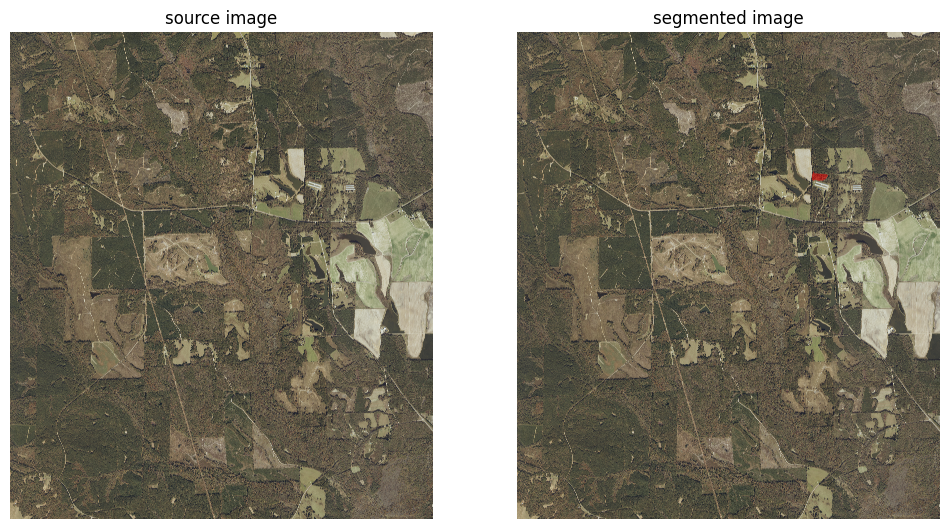

In [29]:
box_annotator = sv.BoxAnnotator(color=sv.Color.RED, color_lookup=sv.ColorLookup.INDEX)
mask_annotator = sv.MaskAnnotator(color=sv.Color.RED, color_lookup=sv.ColorLookup.INDEX)

detections = sv.Detections(
    xyxy=sv.mask_to_xyxy(masks=masks),
    mask=masks
)
detections = detections[detections.area == np.max(detections.area)]

source_image = box_annotator.annotate(scene=image_bgr.copy(), detections=detections)
segmented_image = mask_annotator.annotate(scene=image_bgr.copy(), detections=detections)

sv.plot_images_grid(
    images=[source_image, segmented_image],
    grid_size=(1, 2),
    titles=['source image', 'segmented image']
)

In [45]:
import os
import glob
import ast
import cv2
import numpy as np
import pandas as pd
import json

def draw_annotations_on_jpg_image(jpg_image_path, object_infos, output_path):
    """
    Overlays bounding boxes, masks, and class/conf labels on a JPG image.
    """
    img = cv2.imread(jpg_image_path)
    if img is None:
        print(f"Image not found: {jpg_image_path}")
        return
    overlay = img.copy()
    height, width = img.shape[:2]
    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = 1.2
    thickness = 2

    for idx, obj in enumerate(object_infos):
        try:
            # --- BBOX ---
            x1 = int(round(obj['bbox_x1']))
            y1 = int(round(obj['bbox_y1']))
            x2 = int(round(obj['bbox_x2']))
            y2 = int(round(obj['bbox_y2']))

            # Sanity check
            if not (0 <= x1 < width and 0 <= x2 <= width and 0 <= y1 < height and 0 <= y2 <= height):
                print(f"WARNING: bbox ({x1},{y1},{x2},{y2}) out of bounds for {jpg_image_path} size {img.shape}")
                continue

            cv2.rectangle(overlay, (x1, y1), (x2, y2), (0, 255, 0), 3)

            # --- LABEL ---
            label = f"Cls:{obj.get('class', '')} ({float(obj.get('confidence', 0.0)):.2f})"
            text_size = cv2.getTextSize(label, font, font_scale, thickness)[0]
            text_origin = (x1, max(y1 - 5, text_size[1]))
            cv2.putText(overlay, label, text_origin, font, font_scale, (0, 0, 0), thickness+2)
            cv2.putText(overlay, label, text_origin, font, font_scale, (255, 255, 255), thickness)

            # --- MASK (optional) ---
            if 'mask_points' in obj and pd.notna(obj['mask_points']):
                try:
                    mask_points = np.array(ast.literal_eval(obj['mask_points']), dtype=np.int32)
                    if mask_points.ndim == 2 and mask_points.shape[0] >= 3:
                        mask_img = np.zeros_like(img)
                        cv2.fillPoly(mask_img, [mask_points], (0, 0, 255))
                        cv2.polylines(mask_img, [mask_points], isClosed=True, color=(0, 0, 255), thickness=2)
                        overlay = cv2.addWeighted(overlay, 1.0, mask_img, 0.3, 0)
                except Exception as e:
                    print(f"Mask error idx={idx}: {e}")
        except Exception as e:
            print(f"Draw error idx={idx}: {e}")

    cv2.imwrite(output_path, overlay)
    print(f"📸 Annotated image saved to: {output_path}")

def run_viz_on_jpgs(csv_sup, jpg_dir, output_dir):
    os.makedirs(output_dir, exist_ok=True)
    df = pd.read_csv(csv_sup)
    
    # Extract the base image name for matching, e.g. from "m_3108503_ne_16_030_20211114.tif_farm0"
    def extract_base(img_tile):
        # Remove everything after ".tif"
        if '.tif' in img_tile:
            base = img_tile.split('.tif')[0]
        else:
            base = os.path.splitext(img_tile)[0]
        return base

    df['base_name'] = df['tile_name'].apply(extract_base)
    jpg_images = glob.glob(os.path.join(jpg_dir, '*.jpg'))
    for jpg_image in jpg_images:
        jpg_base = os.path.splitext(os.path.basename(jpg_image))[0]   # e.g. "m_3108503_ne_16_030_20211114"
        matched_objs = df[df['base_name'] == jpg_base].to_dict(orient='records')
        if len(matched_objs) == 0:
            print(f"No annotations found for: {jpg_base}")
            continue
        output_path = os.path.join(output_dir, jpg_base + '_annotated.jpg')
        draw_annotations_on_jpg_image(jpg_image, matched_objs, output_path)

# ======= Example usage =======
run_viz_on_jpgs(
    csv_sup="CSV_Yolo_test/final_rect.csv", 
    jpg_dir="converted_images",       # Your JPGs directory
    output_dir="annotated_jpgs"       # Where to save outputs
)


📸 Annotated image saved to: annotated_jpgs/m_3108503_se_16_030_20211103_annotated.jpg
📸 Annotated image saved to: annotated_jpgs/m_3108504_sw_16_030_20211114_annotated.jpg
📸 Annotated image saved to: annotated_jpgs/m_3108503_sw_16_030_20211103_annotated.jpg
📸 Annotated image saved to: annotated_jpgs/m_3108501_se_16_030_20211103_annotated.jpg
📸 Annotated image saved to: annotated_jpgs/m_3108501_sw_16_030_20211103_annotated.jpg
📸 Annotated image saved to: annotated_jpgs/m_3108502_sw_16_030_20211103_annotated.jpg
📸 Annotated image saved to: annotated_jpgs/m_3108501_ne_16_030_20211103_annotated.jpg
📸 Annotated image saved to: annotated_jpgs/m_3108501_nw_16_030_20211103_annotated.jpg
📸 Annotated image saved to: annotated_jpgs/m_3108502_ne_16_030_20211103_annotated.jpg
📸 Annotated image saved to: annotated_jpgs/m_3108503_ne_16_030_20211114_annotated.jpg


In [49]:
import os
import glob
import ast
import cv2
import numpy as np
import pandas as pd
import rasterio

def draw_annotations_on_jpg_image_with_gis(jpg_image_path, object_infos, transform, output_path):
    """
    Overlays bounding boxes, masks (using GIS points transformed to pixels), and class/conf labels on a JPG image.
    """
    img = cv2.imread(jpg_image_path)
    if img is None:
        print(f"Image not found: {jpg_image_path}")
        return
    overlay = img.copy()
    height, width = img.shape[:2]
    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = 1.2
    thickness = 2

    for idx, obj in enumerate(object_infos):
        try:
            # --- BBOX (if needed, can convert using GIS) ---
            # Here we assume bbox_x1 etc are already pixel (after GIS-to-pixel mapping)
            x1 = int(round(obj['bbox_x1']))
            y1 = int(round(obj['bbox_y1']))
            x2 = int(round(obj['bbox_x2']))
            y2 = int(round(obj['bbox_y2']))
            if not (0 <= x1 < width and 0 <= x2 <= width and 0 <= y1 < height and 0 <= y2 <= height):
                print(f"WARNING: bbox ({x1},{y1},{x2},{y2}) out of bounds for {jpg_image_path} size {img.shape}")
                continue
            cv2.rectangle(overlay, (x1, y1), (x2, y2), (0, 255, 0), 3)

            # --- LABEL ---
            label = f"Cls:{obj.get('class', '')} ({float(obj.get('confidence', 0.0)):.2f})"
            text_size = cv2.getTextSize(label, font, font_scale, thickness)[0]
            text_origin = (x1, max(y1 - 5, text_size[1]))
            cv2.putText(overlay, label, text_origin, font, font_scale, (0, 0, 0), thickness+2)
            cv2.putText(overlay, label, text_origin, font, font_scale, (255, 255, 255), thickness)

            # --- MASK overlay using GIS information ---
            mask_points_col = obj.get('mask_points_gis') or obj.get('rect_mask_points') or obj.get('mask_points')
            # Try to decode as list of [lon,lat] pairs
            if mask_points_col and isinstance(mask_points_col, str) and mask_points_col.strip().startswith("["):
                try:
                    pts_gis = ast.literal_eval(mask_points_col)
                    if len(pts_gis) >= 3:
                        # Convert GIS to pixel using rasterio transform
                        from rasterio.transform import rowcol
                        pixel_pts = []
                        for pt in pts_gis:
                            if isinstance(pt, (list, tuple)) and len(pt) == 2:
                                lon, lat = pt
                                # rowcol returns (row, col)
                                row, col = rowcol(transform, lon, lat)
                                pixel_pts.append([int(round(col)), int(round(row))])
                        pixel_pts = np.array(pixel_pts, dtype=np.int32)
                        if len(pixel_pts) >= 3:
                            mask_img = np.zeros_like(img)
                            cv2.fillPoly(mask_img, [pixel_pts], (0, 0, 255))
                            cv2.polylines(mask_img, [pixel_pts], isClosed=True, color=(0, 0, 255), thickness=2)
                            overlay = cv2.addWeighted(overlay, 1.0, mask_img, 0.3, 0)
                except Exception as e:
                    print(f"Draw error idx={idx}: {e}")
        except Exception as e:
            print(f"Draw error idx={idx}: {e}")

    cv2.imwrite(output_path, overlay)
    print(f"📸 Annotated image saved to: {output_path}")

import os
import glob
import ast
import cv2
import numpy as np
import pandas as pd
import rasterio

def draw_annotations_on_jpg_image_with_gis(jpg_image_path, object_infos, transform, output_path):
    """
    Overlays bounding boxes, masks (using GIS points transformed to pixels), and class/conf labels on a JPG image.
    """
    img = cv2.imread(jpg_image_path)
    if img is None:
        print(f"Image not found: {jpg_image_path}")
        return
    overlay = img.copy()
    height, width = img.shape[:2]
    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = 1.2
    thickness = 2

    from rasterio.transform import rowcol

    for idx, obj in enumerate(object_infos):
        try:
            # ---- BOUNDING BOX (from GIS to pixel) ----
            # Prefer GIS coordinates if available, else fallback
            # Try: rect_bbox_x1, rect_bbox_y1, ... or bbox_lon/lat columns (adjust to your CSV names)
            lon1, lat1, lon2, lat2 = None, None, None, None

            # Try typical column names for GIS bbox
            for lon_col, lat_col in [
                ('bbox_lon_x1', 'bbox_lat_y1'), 
                ('rect_bbox_lon_x1', 'rect_bbox_lat_y1'),
                ('bbox_lon_xmin', 'bbox_lat_ymin'),
                ('bbox_x1', 'bbox_y1')  # fallback: will not work if not GIS
            ]:
                if lon_col in obj and lat_col in obj:
                    try:
                        lon1 = float(obj[lon_col])
                        lat1 = float(obj[lat_col])
                        lon2 = float(obj[lon_col.replace('1', '2')])
                        lat2 = float(obj[lat_col.replace('1', '2')])
                        break
                    except Exception as e:
                        continue

            # If still None, try rect_mask_points or similar
            if None in (lon1, lat1, lon2, lat2):
                # Try from rect_mask_points polygon
                rect = obj.get('rect_mask_points') or obj.get('mask_points_gis')
                if rect and isinstance(rect, str) and rect.strip().startswith("["):
                    pts_gis = ast.literal_eval(rect)
                    if len(pts_gis) >= 2:
                        lon1, lat1 = pts_gis[0]
                        lon2, lat2 = pts_gis[2]  # assume rectangle
            # Convert both corners to pixel
            if None not in (lon1, lat1, lon2, lat2):
                row1, col1 = rowcol(transform, lon1, lat1)
                row2, col2 = rowcol(transform, lon2, lat2)
                x1, y1 = int(round(col1)), int(round(row1))
                x2, y2 = int(round(col2)), int(round(row2))
                # Sanity check
                if not (0 <= x1 < width and 0 <= x2 <= width and 0 <= y1 < height and 0 <= y2 <= height):
                    print(f"WARNING: GIS-bbox ({x1},{y1},{x2},{y2}) out of bounds for {jpg_image_path} size {img.shape}")
                else:
                    cv2.rectangle(overlay, (x1, y1), (x2, y2), (0, 255, 0), 3)
                    # Label
                    label = f"Cls:{obj.get('class', '')} ({float(obj.get('confidence', 0.0)):.2f})"
                    text_size = cv2.getTextSize(label, font, font_scale, thickness)[0]
                    text_origin = (x1, max(y1 - 5, text_size[1]))
                    cv2.putText(overlay, label, text_origin, font, font_scale, (0, 0, 0), thickness+2)
                    cv2.putText(overlay, label, text_origin, font, font_scale, (255, 255, 255), thickness)
            else:
                print(f"WARNING: No bbox GIS coords for idx={idx}")

            # ---- MASK overlay using GIS information ----
            mask_points_col = obj.get('mask_points_gis') or obj.get('rect_mask_points') or obj.get('mask_points')
            # Try to decode as list of [lon,lat] pairs
            if mask_points_col and isinstance(mask_points_col, str) and mask_points_col.strip().startswith("["):
                try:
                    pts_gis = ast.literal_eval(mask_points_col)
                    if len(pts_gis) >= 3:
                        # Convert GIS to pixel using rasterio transform
                        pixel_pts = []
                        for pt in pts_gis:
                            if isinstance(pt, (list, tuple)) and len(pt) == 2:
                                lon, lat = pt
                                row, col = rowcol(transform, lon, lat)
                                pixel_pts.append([int(round(col)), int(round(row))])
                        pixel_pts = np.array(pixel_pts, dtype=np.int32)
                        if len(pixel_pts) >= 3:
                            mask_img = np.zeros_like(img)
                            cv2.fillPoly(mask_img, [pixel_pts], (0, 0, 255))
                            cv2.polylines(mask_img, [pixel_pts], isClosed=True, color=(0, 0, 255), thickness=2)
                            overlay = cv2.addWeighted(overlay, 1.0, mask_img, 0.3, 0)
                except Exception as e:
                    print(f"Draw error idx={idx}: {e}")
        except Exception as e:
            print(f"Draw error idx={idx}: {e}")

    cv2.imwrite(output_path, overlay)
    print(f"📸 Annotated image saved to: {output_path}")


# Usage example:
run_viz_on_jpgs_with_gis(
    csv_sup="CSV_Yolo_test/final_rect.csv", 
    jpg_dir="converted_images",        # Directory with JPGs
    output_dir="annotated_jpgs_gis",   # Output folder
    geotiff_dir="test_sample"          # Directory with original GeoTIFFs
)


📸 Annotated image saved to: annotated_jpgs_gis/m_3108503_se_16_030_20211103_gis_annotated.jpg
📸 Annotated image saved to: annotated_jpgs_gis/m_3108504_sw_16_030_20211114_gis_annotated.jpg
📸 Annotated image saved to: annotated_jpgs_gis/m_3108503_sw_16_030_20211103_gis_annotated.jpg
📸 Annotated image saved to: annotated_jpgs_gis/m_3108501_se_16_030_20211103_gis_annotated.jpg
📸 Annotated image saved to: annotated_jpgs_gis/m_3108501_sw_16_030_20211103_gis_annotated.jpg
📸 Annotated image saved to: annotated_jpgs_gis/m_3108502_sw_16_030_20211103_gis_annotated.jpg
📸 Annotated image saved to: annotated_jpgs_gis/m_3108501_ne_16_030_20211103_gis_annotated.jpg
📸 Annotated image saved to: annotated_jpgs_gis/m_3108501_nw_16_030_20211103_gis_annotated.jpg
📸 Annotated image saved to: annotated_jpgs_gis/m_3108502_ne_16_030_20211103_gis_annotated.jpg
📸 Annotated image saved to: annotated_jpgs_gis/m_3108503_ne_16_030_20211114_gis_annotated.jpg


In [53]:
import os
import ast
import cv2
import numpy as np
import pandas as pd
import rasterio
from rasterio.transform import rowcol
from tqdm import tqdm

import torch
from segment_anything import sam_model_registry, SamPredictor

# -------- SAM Setup --------
CHECKPOINT_PATH = "weights/sam_vit_h_4b8939.pth"
MODEL_TYPE = "vit_h"
DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
sam = sam_model_registry[MODEL_TYPE](checkpoint=CHECKPOINT_PATH).to(device=DEVICE)
sam_predictor = SamPredictor(sam)

# -------- Helper: Get pixel bbox from GIS --------
def gis_bbox_to_pixel(bbox_gis, transform):
    # bbox_gis: [lon1, lat1, lon2, lat2]  (top-left and bottom-right)
    lon1, lat1, lon2, lat2 = bbox_gis
    row1, col1 = rowcol(transform, lon1, lat1)
    row2, col2 = rowcol(transform, lon2, lat2)
    x1, y1 = int(round(col1)), int(round(row1))
    x2, y2 = int(round(col2)), int(round(row2))
    return x1, y1, x2, y2

# --------- Main Visualization ---------
def run_viz_on_jpgs_with_gis_and_sam(
    csv_sup, jpg_dir, output_dir, geotiff_dir,
    class_label_col="class", conf_col="confidence"
):
    os.makedirs(output_dir, exist_ok=True)
    df = pd.read_csv(csv_sup)
    jpg_files = {os.path.splitext(os.path.basename(f))[0]: f for f in os.listdir(jpg_dir) if f.lower().endswith(".jpg")}
    tiff_files = {os.path.splitext(os.path.basename(f))[0]: f for f in os.listdir(geotiff_dir) if f.lower().endswith(('.tif', '.tiff'))}

    for img_name, jpg_path in tqdm(jpg_files.items()):
        # Filter objects for this image
        objects = df[df['tile_name'].str.startswith(img_name)].to_dict(orient='records')
        if not objects:
            continue

        # Find corresponding geotiff for raster transform
        tif_candidates = [f for f in tiff_files if f in img_name]
        if not tif_candidates:
            print(f"No matching GeoTIFF for {img_name}")
            continue
        geotiff_path = os.path.join(geotiff_dir, tiff_files[tif_candidates[0]])

        with rasterio.open(geotiff_path) as src:
            transform = src.transform

        jpg_img = cv2.imread(os.path.join(jpg_dir, os.path.basename(jpg_path)))
        if jpg_img is None:
            print(f"Cannot read {jpg_path}")
            continue
        overlay = jpg_img.copy()

        for obj in objects:
            try:
                # 1. Get bbox from GIS (modify these columns as per your CSV)
                bbox_gis = None
                if all(k in obj for k in ['bbox_lon_x1', 'bbox_lat_y1', 'bbox_lon_x2', 'bbox_lat_y2']):
                    bbox_gis = [
                        float(obj['bbox_lon_x1']), float(obj['bbox_lat_y1']),
                        float(obj['bbox_lon_x2']), float(obj['bbox_lat_y2'])
                    ]
                elif all(k in obj for k in ['rect_bbox_lon_x1', 'rect_bbox_lat_y1', 'rect_bbox_lon_x2', 'rect_bbox_lat_y2']):
                    bbox_gis = [
                        float(obj['rect_bbox_lon_x1']), float(obj['rect_bbox_lat_y1']),
                        float(obj['rect_bbox_lon_x2']), float(obj['rect_bbox_lat_y2'])
                    ]
                else:
                    print(f"Skipping: missing GIS bbox columns in {obj.get('tile_name')}")
                    continue

                x1, y1, x2, y2 = gis_bbox_to_pixel(bbox_gis, transform)
                x1, x2 = np.clip([x1, x2], 0, jpg_img.shape[1]-1)
                y1, y2 = np.clip([y1, y2], 0, jpg_img.shape[0]-1)

                if x2 <= x1 or y2 <= y1:
                    continue

                # 2. Crop the bbox region, run SAM
                roi_rgb = cv2.cvtColor(jpg_img[y1:y2, x1:x2], cv2.COLOR_BGR2RGB)
                if roi_rgb.size == 0:
                    continue
                sam_predictor.set_image(roi_rgb)
                box = np.array([0, 0, x2-x1, y2-y1])  # Whole ROI
                masks, scores, logits = sam_predictor.predict(box=box, multimask_output=True)
                if masks is None or len(masks) == 0:
                    continue
                mask = masks[np.argmax(scores)]

                # 3. Overlay the SAM mask (convert to original image coords)
                mask_full = np.zeros(jpg_img.shape[:2], dtype=np.uint8)
                mask_resized = cv2.resize(mask.astype(np.uint8), (x2-x1, y2-y1), interpolation=cv2.INTER_NEAREST)
                mask_full[y1:y2, x1:x2] = mask_resized

                mask_img = np.zeros_like(jpg_img)
                mask_img[mask_full > 0] = [0, 0, 255]  # Red mask

                overlay = cv2.addWeighted(overlay, 1.0, mask_img, 0.4, 0)

                # 4. Draw bbox and label
                cv2.rectangle(overlay, (x1, y1), (x2, y2), (0, 255, 0), 2)
                label = f"Cls:{obj.get(class_label_col, '')} ({float(obj.get(conf_col, 0.0)):.2f})"
                font = cv2.FONT_HERSHEY_SIMPLEX
                font_scale = 1.0
                thickness = 2
                text_size = cv2.getTextSize(label, font, font_scale, thickness)[0]
                text_origin = (x1, max(y1 - 5, text_size[1]))
                cv2.putText(overlay, label, text_origin, font, font_scale, (0,0,0), thickness+2)
                cv2.putText(overlay, label, text_origin, font, font_scale, (255,255,255), thickness)

            except Exception as e:
                print(f"Error {obj.get('tile_name')}: {e}")

        out_path = os.path.join(output_dir, img_name + "_sam_annotated.jpg")
        cv2.imwrite(out_path, overlay)
        print(f"Saved: {out_path}")

# ---------- Usage ----------
run_viz_on_jpgs_with_gis_and_sam(
    csv_sup="CSV_Yolo_test/final_rect.csv", 
    jpg_dir="converted_images",
    output_dir="annotated_jpgs_gis_sam",
    geotiff_dir="test_sample"
)


 10%|████████▍                                                                           | 1/10 [00:50<07:35, 50.57s/it]

Saved: annotated_jpgs_gis_sam/m_3108503_se_16_030_20211103_sam_annotated.jpg


 20%|████████████████▌                                                                  | 2/10 [04:32<20:10, 151.31s/it]

Saved: annotated_jpgs_gis_sam/m_3108504_sw_16_030_20211114_sam_annotated.jpg


 30%|████████████████████████▉                                                          | 3/10 [05:19<12:05, 103.61s/it]

...

Saved: annotated_jpgs_gis_sam/m_3108501_nw_16_030_20211103_sam_annotated.jpg


 90%|██████████████████████████████████████████████████████████████████████████▋        | 9/10 [54:54<05:55, 355.17s/it]

Saved: annotated_jpgs_gis_sam/m_3108502_ne_16_030_20211103_sam_annotated.jpg


100%|██████████████████████████████████████████████████████████████████████████████████| 10/10 [55:53<00:00, 335.38s/it]

Saved: annotated_jpgs_gis_sam/m_3108503_ne_16_030_20211114_sam_annotated.jpg


In [54]:
import os
import cv2
import numpy as np
import pandas as pd
import rasterio
from rasterio.transform import rowcol
from tqdm import tqdm
import torch
from segment_anything import sam_model_registry, SamPredictor

# -------- SAM Setup --------
CHECKPOINT_PATH = "weights/sam_vit_h_4b8939.pth"
MODEL_TYPE = "vit_h"
DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
sam = sam_model_registry[MODEL_TYPE](checkpoint=CHECKPOINT_PATH).to(device=DEVICE)
sam_predictor = SamPredictor(sam)

# Helper: Project GIS bbox to pixel
def gis_bbox_to_pixel(bbox_gis, transform):
    # bbox_gis: [lat1, lon1, lat2, lon2]
    lat1, lon1, lat2, lon2 = bbox_gis
    row1, col1 = rowcol(transform, lon1, lat1)
    row2, col2 = rowcol(transform, lon2, lat2)
    x1, y1 = int(round(col1)), int(round(row1))
    x2, y2 = int(round(col2)), int(round(row2))
    # Ensure top-left, bottom-right order
    x1, x2 = sorted([x1, x2])
    y1, y2 = sorted([y1, y2])
    return x1, y1, x2, y2

def run_viz_on_geotiffs_with_sam(
    csv_sup, geotiff_dir, output_dir,
    class_label_col="class", conf_col="confidence",
    lat1_col="bbox_lat_y1", lon1_col="bbox_lon_x1", lat2_col="bbox_lat_y2", lon2_col="bbox_lon_x2",
    tile_col="tile_name"
):
    os.makedirs(output_dir, exist_ok=True)
    df = pd.read_csv(csv_sup)
    tiff_files = {os.path.splitext(os.path.basename(f))[0]: f for f in os.listdir(geotiff_dir) if f.lower().endswith(('.tif', '.tiff'))}

    for tile_base, tiff_file in tqdm(tiff_files.items()):
        objects = df[df[tile_col].str.startswith(tile_base)].to_dict(orient='records')
        if not objects:
            continue

        geotiff_path = os.path.join(geotiff_dir, tiff_file)
        with rasterio.open(geotiff_path) as src:
            img = src.read([1, 2, 3])  # Only first 3 bands, assumes RGB GeoTIFF
            transform = src.transform

        # Rasterio reads as [C,H,W], convert to HWC, uint8 if necessary
        img = np.transpose(img, (1, 2, 0))
        if img.dtype != np.uint8:
            img = ((img - img.min()) / (img.max() - img.min()) * 255).astype(np.uint8)
        overlay = img.copy()

        for obj in objects:
            try:
                # Extract GIS bbox columns (lat/lon order)
                bbox_gis = [
                    float(obj[lat1_col]), float(obj[lon1_col]),
                    float(obj[lat2_col]), float(obj[lon2_col])
                ]
                x1, y1, x2, y2 = gis_bbox_to_pixel(bbox_gis, transform)
                # Clip bbox to image bounds
                x1, x2 = np.clip([x1, x2], 0, overlay.shape[1] - 1)
                y1, y2 = np.clip([y1, y2], 0, overlay.shape[0] - 1)

                if x2 <= x1 or y2 <= y1:
                    continue

                # Crop and run SAM
                roi_rgb = overlay[y1:y2, x1:x2]
                if roi_rgb.size == 0:
                    continue
                sam_predictor.set_image(roi_rgb)
                box = np.array([0, 0, x2-x1, y2-y1])  # Use full crop
                masks, scores, logits = sam_predictor.predict(box=box, multimask_output=True)
                if masks is None or len(masks) == 0:
                    continue
                mask = masks[np.argmax(scores)]

                # Overlay the mask back to the large image
                mask_full = np.zeros(overlay.shape[:2], dtype=np.uint8)
                mask_resized = cv2.resize(mask.astype(np.uint8), (x2-x1, y2-y1), interpolation=cv2.INTER_NEAREST)
                mask_full[y1:y2, x1:x2] = mask_resized

                mask_img = np.zeros_like(overlay)
                mask_img[mask_full > 0] = [0, 0, 255]  # Red
                overlay = cv2.addWeighted(overlay, 1.0, mask_img, 0.4, 0)

                # Draw bbox and label
                cv2.rectangle(overlay, (x1, y1), (x2, y2), (0, 255, 0), 2)
                label = f"Cls:{obj.get(class_label_col, '')} ({float(obj.get(conf_col, 0.0)):.2f})"
                font = cv2.FONT_HERSHEY_SIMPLEX
                font_scale = 1.0
                thickness = 2
                text_size = cv2.getTextSize(label, font, font_scale, thickness)[0]
                text_origin = (x1, max(y1 - 5, text_size[1]))
                cv2.putText(overlay, label, text_origin, font, font_scale, (0, 0, 0), thickness+2)
                cv2.putText(overlay, label, text_origin, font, font_scale, (255, 255, 255), thickness)

            except Exception as e:
                print(f"Error {obj.get(tile_col)}: {e}")

        out_path = os.path.join(output_dir, tile_base + "_sam_annotated.png")
        cv2.imwrite(out_path, overlay)
        print(f"Saved: {out_path}")

# ---------- Usage ----------
run_viz_on_geotiffs_with_sam(
    csv_sup="CSV_Yolo_test/final_rect_highest_conf.csv",
    geotiff_dir="test_sample",
    output_dir="annotated_geotiff_sam"
)


 10%|████████▎                                                                          | 1/10 [03:46<34:02, 226.99s/it]

Saved: annotated_geotiff_sam/m_3108502_sw_16_030_20211103_sam_annotated.png


 20%|████████████████▌                                                                  | 2/10 [07:14<28:44, 215.60s/it]

Saved: annotated_geotiff_sam/m_3108501_se_16_030_20211103_sam_annotated.png


 30%|████████████████████████▉                                                          | 3/10 [10:55<25:25, 217.89s/it]

...

Saved: annotated_geotiff_sam/m_3108502_ne_16_030_20211103_sam_annotated.png


 90%|██████████████████████████████████████████████████████████████████████████▋        | 9/10 [21:34<02:20, 140.79s/it]

Saved: annotated_geotiff_sam/m_3108501_ne_16_030_20211103_sam_annotated.png


100%|██████████████████████████████████████████████████████████████████████████████████| 10/10 [22:34<00:00, 135.44s/it]

Saved: annotated_geotiff_sam/m_3108501_nw_16_030_20211103_sam_annotated.png
